# Ej. 3 · Exploración según la mejora (1,5 puntos)

**Objetivo (enunciado):** que ε no dependa del número de episodios y baje conforme mejora el agente. Hay que responder dos
preguntas: **¿cómo determinamos que el algoritmo ha mejorado?** y **¿cómo trasladamos esa mejora a ε?** El número de
episodios puede seguir fijo.

### Qué cambia respecto al ej. 2

| Bloque | Cambio | Decisión |
|---|---|---|
| Decaimiento de ε | `LinearDecay` (por episodio) → `ImprovementEpsilon` (por evaluación) | D-3.1 |
| Bucle | Evaluación greedy cada 25 episodios en la rejilla fija, que ahora **decide** ε (en el ej. 2 solo se registraba) | D-3.1 |
| Resto | Igual que la configuración final del ej. 2: `TrackingCierre` (c = 20), γ = 0,9, buffer 10.000, aprender cada 8 pasos | D-2.2…D-2.7 |

### Plan del notebook, por puntos

| Punto | Pregunta | Qué se decide | Estado |
|---|---|---|---|
| **1** | ¿Cómo sabemos que el agente ha mejorado? | La métrica E y sus acompañantes | ✔ este notebook |
| **2** | ¿Contra qué lo comparamos? | Las referencias E0 (sin aprender) y E* (TWAP determinista) | ✔ este notebook |
| **3** | ¿Cómo pasa la mejora a ε? | La función progreso → ε, el margen y la subida de ε | ✔ este notebook |
| **4** | ¿Cómo demostramos que funciona? | ε lineal frente a ε por mejora, 3 semillas | ✔ este notebook |
| **5** | Resultados y conclusión | Cifras finales y lectura | ✔ este notebook |

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))   # ejecutar desde notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import data as dt, rewards as rw, exploration as ex, protocol as pr, plots as pl, ej3
from common.env import BestExecutionEnv
from common.agents import DDQNAgent, TWAPAgent
pd.set_option("display.precision", 2)
%matplotlib inline

### Datos y configuración

Repsol (D-0.2), días de train y la rejilla fija de 27 episodios (N ∈ {400, 500, 600} × ρ ∈ {0,075; 0,10; 0,125} × 3 días,
D-0.3). El agente es **el del ej. 2 en su configuración final** (D-2.2…D-2.7): recompensa de seguimiento con cierre
`TrackingCierre` con recorte c = 20 títulos (también en la evaluación), γ = 0,9, α = 0,001, batch 64, red 2 → 32 → 32 → 2,
buffer de 10.000, aprender cada 8 pasos, red objetivo cada 1.000, 300 episodios y 25 de llenado. En el ej. 2 replica el TWAP:
0,91 títulos de error máximo con 3 semillas (TWAP 0,90). Lo único que cambia aquí es el plan de ε.

In [2]:
ASSET = "REP"                      # D-0.2
DATA = dt.load(ASSET)
train = DATA["train"]
GRID = pr.make_grid(train, n_days=3, seed=0)   # rejilla fija de evaluación (D-0.3)
SC = ej3.SCENARIOS["final"]                    # configuración final del ej. 2 (D-2.2…D-2.7)
CFG = {k: SC[k] for k in ("gamma", "alpha", "buffer_size", "batch_size", "hidden_neurons")}
REWARD = ej3.make_reward(SC)                   # TrackingCierre(γ = 0,9, c = 20)
TWAP_GRID, RAND_GRID = pr.load_df("00_twap_grid"), pr.load_df("00_random_grid")   # referencias del notebook 00
TWAP_ERR = TWAP_GRID.max_err.mean()
print(dt.summary(DATA)); print(len(GRID), "episodios de evaluación · error máx. del TWAP determinista:", round(TWAP_ERR, 2))

{'train': {'dias': 60, 'filas_por_dia': [3177, 3178, 3179]}, 'val': {'dias': 30, 'filas_por_dia': [3179, 3180, 3181]}, 'test': {'dias': 30, 'filas_por_dia': [3179, 3180, 3181]}}
27 episodios de evaluación · error máx. del TWAP determinista: 0.9


---
## Punto 1 · ¿Cómo sabemos que el agente ha mejorado?

Para bajar ε «conforme mejora» hay que medir la mejora con algo que **no dependa de ε**. Tres comprobaciones, de la más
general a la más concreta: qué curva mirar (1.a), qué métrica no sirve (1.b) y qué resumen del error usar (1.c).

### 1.a · La recompensa de entrenamiento engaña

**Decisión:** la mejora se mide con una **evaluación greedy** (ε = 0) cada 25 episodios en los **mismos** 27 episodios de la
rejilla, nunca con la recompensa de entrenamiento.

**Por qué:** es el ejemplo del *cliff walking* de clase: con ε lineal la curva de entrenamiento «se estabiliza» justo cuando
ε toca el mínimo, pero evaluando sin explorar el agente había aprendido mucho antes (04 §2.3; T07 ~00:20-00:22). Hay que
parar la exploración y evaluar en varios episodios, no en uno (04 §3.2; T06 ~03:16-03:17; APP p.90). Usar la recompensa de
entrenamiento como mejora sería circular (riesgo M4, 10 §7.2 y §7.6).

**Experimento:** el entrenamiento del ej. 2 tal cual: ε lineal de 1 a 0,05 en 150 episodios (la mitad de 300), semilla 0,
con evaluación greedy cada 25 episodios. Es la misma ejecución que la pareja «ε lineal, semilla 0» del Punto 4, así que se
cachea una sola vez en `results/ej3_p4_runs/`.

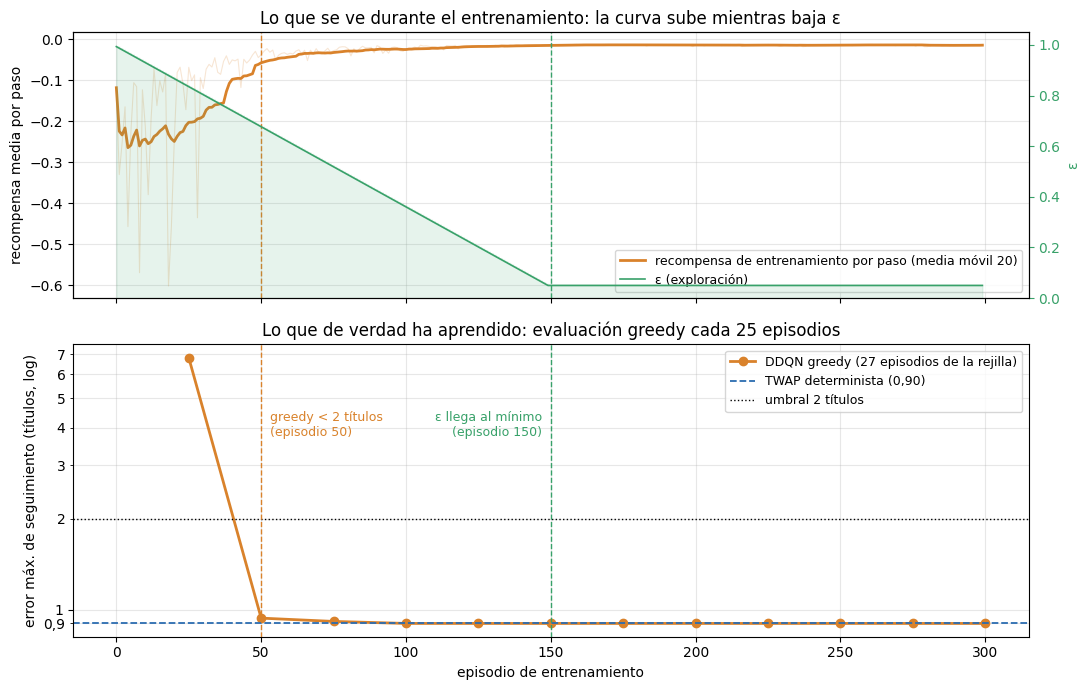

In [3]:
ej3.run_one("final", "lineal", 0, target=TWAP_ERR)          # ~2 min la primera vez; después se lee de la caché
ep1, ev1 = ej3.load_run("final", "lineal", 0)
EPS_MIN_EP = int(ep1.episode[ep1.epsilon <= 0.05 + 1e-9].min()) + 1
ej3.plot_train_vs_greedy(ep1, ev1, TWAP_ERR, EPS_MIN_EP, save_as="ej3_p1a_entrenamiento_vs_greedy");

In [4]:
rps = (ep1.reward / ep1.steps).rolling(20, min_periods=1).mean()
print(f"greedy < 2 títulos en el episodio {ej3.first_below(ev1)} · ε al mínimo en el episodio {EPS_MIN_EP}")
print(f"correlación entre la recompensa por paso (media móvil 20) y ε: {np.corrcoef(rps, ep1.epsilon)[0, 1]:.2f}")
ev1.set_index("episode")[["max_err", "mean_err", "completed", "epsilon"]].T

greedy < 2 títulos en el episodio 50 · ε al mínimo en el episodio 150
correlación entre la recompensa por paso (media móvil 20) y ε: -0.85


episode,25,50,75,100,125,150,175,200,225,250,275,300
max_err,6.82,0.94,0.91,0.90,0.90,0.90,0.90,0.90,0.90,0.90,0.90,0.90
mean_err,3.38,0.31,0.30,0.30,0.27,0.27,0.27,0.27,0.28,0.29,0.29,0.27
completed,0.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
epsilon,0.84,0.68,0.53,0.37,0.21,0.05,0.05,0.05,0.05,0.05,0.05,0.05


**Lectura.** Es el *cliff walking* de clase con datos de bolsa. Mirando solo la curva de entrenamiento, el agente «aprende» poco a poco y se estabiliza hacia el episodio 150, justo cuando ε llega al mínimo: la recompensa por paso sube mientras ε baja (correlación de −0,85 entre su media móvil y ε). La evaluación greedy dice otra cosa: la política **baja de 2 títulos en el episodio 50** (0,94) y desde el 100 iguala al TWAP (0,90) en todas las evaluaciones. Con ε lineal, el agente pasa 100 episodios, dos tercios del entrenamiento, explorando mucho (ε de 0,68 a 0,05) con una política que ya sabía lo que tenía que hacer. Esa es la ineficiencia que el ej. 3 quiere quitar.

La curva de entrenamiento mezcla cuatro cosas: la política, la exploración (con ε alto la mitad de las acciones son al azar),
episodios de distinto N y n (la recompensa por paso no es comparable entre ellos) y una red que cambia dentro del propio
episodio. La evaluación greedy aísla la primera: misma rejilla, sin explorar y con la red congelada.

### 1.b · El slippage no separa una política buena de una mala

**Decisión:** el slippage frente al VWAP de mercado **no** es la métrica de mejora del ej. 3; se registra solo como
información.

**Por qué:** el agente ve el estado [T, V] (D-2.1): no ve el mercado, así que no puede optimizar el precio, y su recompensa
(D-2.2) solo premia seguir el plan. Una métrica que el agente no controla mide sobre todo la suerte del día. Se comprueba sin
entrenar nada, con las dos políticas de referencia del notebook 00 en los 27 episodios de la rejilla.

la aleatoria tiene mejor slippage que el TWAP en 11 de 27 episodios


,error máx. (títulos),error medio (títulos),completadas (%),pendientes (títulos),t_fin (% de N),slippage (pb),slippage std (pb),error máx. std
TWAP,0.90,0.44,100.00,0.00,98.08,-1.77,1.35,0.02
aleatoria,7.18,3.24,48.15,2.41,94.02,-2.43,1.82,3.60


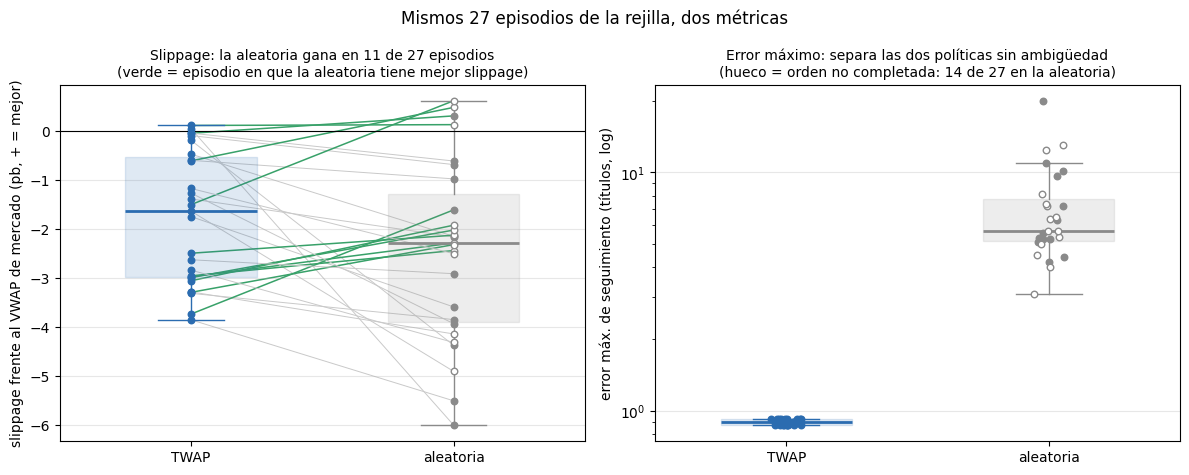

In [5]:
fig, wins = ej3.plot_slippage_vs_error(TWAP_GRID, RAND_GRID, save_as="ej3_p1b_slippage_vs_error")
print(f"la aleatoria tiene mejor slippage que el TWAP en {wins} de {len(GRID)} episodios")
ej3.metrics_table({"TWAP": TWAP_GRID, "aleatoria": RAND_GRID}).assign(
    **{"slippage std (pb)": [TWAP_GRID.slippage_bps.std(), RAND_GRID.slippage_bps.std()],
       "error máx. std": [TWAP_GRID.max_err.std(), RAND_GRID.max_err.std()]})

**Lectura.** Con los mismos 27 episodios, la política aleatoria tiene **mejor slippage que el TWAP en 11 de 27** (líneas verdes) y las dos distribuciones se solapan (TWAP −1,77 ± 1,35 pb; aleatoria −2,43 ± 1,82 pb). Además, la aleatoria solo completa el 48 % de las órdenes (huecos), así que su slippage se calcula sobre órdenes a medias. El error máximo, en cambio, las separa sin solaparse: 0,90 ± 0,02 títulos frente a 7,18 ± 3,60.

El slippage se seguirá guardando en todas las evaluaciones y será protagonista en el ej. 4 (idea A: añadir información de
mercado al estado y un término de precio a la recompensa).

### 1.c · Error máximo frente a error medio

**Decisión:** el resumen del error de seguimiento en un episodio es su **máximo**, $\max_t |e_t - t\,n/N|$, no su media.

**Por qué:** el TWAP determinista garantiza un error ≤ 1 título en **todo** momento; la media premia ir bien casi siempre y
esconde un fallo concentrado al final. Ejemplo: una política **olvidadiza** que sigue la regla del TWAP pero deja de comprar
en el último 10 % del episodio (`ej3.Forgetful`, compra si V ≥ T y T > 0,1). Es justo el fallo que importa en una orden
CARE: no terminar.

,error máx. (títulos),error medio (títulos),completadas (%),pendientes (títulos),t_fin (% de N),slippage (pb)
TWAP,0.90,0.44,100.00,0.00,98.08,-1.77
olvidadiza,4.78,0.63,0.00,4.78,100.00,-2.31
aleatoria,7.18,3.24,48.15,2.41,94.02,-2.43


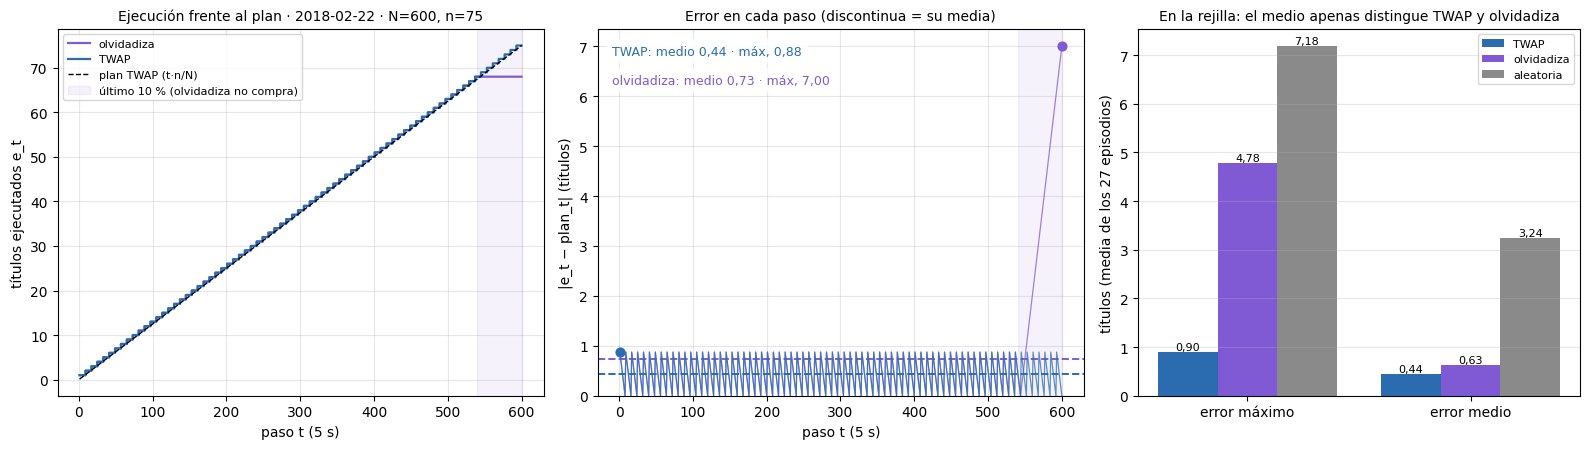

In [6]:
forgetful = ej3.Forgetful(cutoff=0.1)
FORG_GRID = pr.evaluate(forgetful, train, GRID, reward=REWARD, with_twap=False)
TAB = ej3.metrics_table({"TWAP": TWAP_GRID, "olvidadiza": FORG_GRID, "aleatoria": RAND_GRID})
CFG_EX = max(GRID, key=lambda c: c["vol_care"])            # episodio con la orden más grande (N=600, n=75)
ej3.plot_max_vs_mean({"TWAP": TWAPAgent(), "olvidadiza": forgetful}, train, CFG_EX, TAB,
                     save_as="ej3_p1c_max_vs_medio")
TAB

**Lectura.** En la rejilla, el error **medio** de la olvidadiza es 0,63 títulos, apenas 0,2 más que el TWAP (0,44), y queda muy lejos de la aleatoria (3,24): por la media parecería casi un TWAP. El error **máximo** la delata: 4,78 títulos, que son exactamente los títulos que deja pendientes (≈ n · 0,1), y **no completa ninguna de las 27 órdenes**. En el episodio del ejemplo (N = 600, n = 75) el error medio es 0,73 y el máximo 7,0, todo concentrado en el último 10 %. Con el máximo, «ir bien casi siempre» no compensa no terminar.

### Decisión del Punto 1

| Papel | Métrica | Por qué |
|---|---|---|
| **Métrica de mejora E** | **Error máximo de seguimiento medio en la rejilla** (títulos; greedy, 27 episodios, cada 25 episodios) | No depende de ε (1.a), mide lo que el agente controla (1.b) y castiga el fallo puntual (1.c). Es la que ya usan `protocol.train` e `ImprovementEpsilon` |
| Acompañante | % de órdenes completadas | Lectura de negocio. Si una orden no termina, max_err ≥ títulos pendientes, así que E ya lo castiga |
| Acompañante | Títulos pendientes | Cuánto falta, no solo si falta |
| Acompañante | t_fin (% de N) | Terminar demasiado pronto también es malo: con γ = 0,99 y sin cierre el agente acababa al 17 % del tiempo (D-2.3, D-2.6) |
| Informativa | Slippage frente al VWAP (pb) | Se registra; con [T, V] no es optimizable (1.b). Pasa a ser objetivo en el ej. 4 |

**Limitación.** La rejilla usa días de **train**: el enunciado del ej. 2 lo permite («basta con imágenes correctas en train»),
pero el profesor recomendó validar en datos no vistos en modo ejecución (APP p.90). Se deja anotado para el Punto 5.

---
## Punto 2 · ¿Contra qué lo comparamos? (E0 y E\*)

E en títulos no dice por sí sola si el agente va bien: 15 títulos es mucho si el objetivo es 0,9 y poco si se parte de 50.
Para convertir E en progreso hacen falta dos referencias, el punto de partida **E0** y el objetivo **E\***:

$$p = \mathrm{clip}\!\left(\frac{E_0 - E}{E_0 - E^*},\ 0,\ 1\right)$$

### 2.a · Por qué un objetivo explícito

**Decisión:** el objetivo es el **TWAP determinista**, E\* = su error máximo medio en la rejilla.

**Por qué:** en clase, el plan de bajada de ε se hace **respecto al objetivo**, no por episodios: «ya está a mitad del
objetivo, puedo bajar un poco la exploración» (04 §3.3; T06 ~03:19). Si no se conoce el coste de oportunidad, se fija un
nivel de aspiración con un *benchmark*, como un algoritmo clásico sin ML (APP p.66; T06 ~03:19-03:24), y no basta con saber
si ha subido o bajado: hay que saber **a qué distancia** se está (T06 ~03:22-03:23). En ejecución, el *benchmark* natural es
el TWAP programado sobre los históricos (T07 ~01:47), que es además lo que el ej. 2 pide replicar.

### 2.b · La escalera de referencias en la rejilla

Dónde queda cada política en la misma métrica y los mismos 27 episodios: dos que no aprenden nada (no comprar y la red recién
creada, semilla 0), la aleatoria, el agente del Punto 1 y el TWAP.

{'no comprar nada': np.float64(49.89), 'DDQN 1.ª evaluación (ep. 25)': np.float64(6.82), 'red sin entrenar (semilla 0)': np.float64(44.7), 'aleatoria (p = ρ)': np.float64(7.18), 'DDQN mejor punto del Punto 1': np.float64(0.9), 'TWAP determinista (E*)': np.float64(0.9)}
red sin entrenar: completa 100%, termina al 10.0% de N


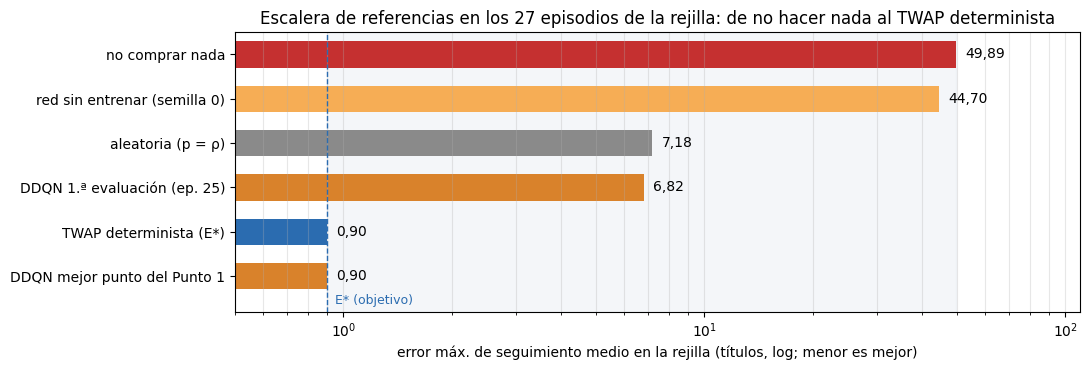

In [7]:
NOBUY_GRID = pr.evaluate(ej3.NoBuy(), train, GRID, reward=REWARD, with_twap=False)
pr.set_seeds(0)
UNTRAINED_GRID = pr.evaluate(DDQNAgent(BestExecutionEnv(train, reward=REWARD, seed=0), seed=0, **CFG),
                             train, GRID, reward=REWARD, with_twap=False)
LADDER = {"no comprar nada": NOBUY_GRID.max_err.mean(), "DDQN 1.ª evaluación (ep. 25)": ev1.max_err.iloc[0],
          "red sin entrenar (semilla 0)": UNTRAINED_GRID.max_err.mean(), "aleatoria (p = ρ)": RAND_GRID.max_err.mean(),
          "DDQN mejor punto del Punto 1": ev1.max_err.min(), "TWAP determinista (E*)": TWAP_ERR}
LCOL = dict(zip(LADDER, [ej3.COLORS[k] for k in ("no comprar", "DDQN", "sin entrenar", "aleatoria", "DDQN", "TWAP")]))
ej3.plot_ladder(LADDER, LCOL, TWAP_ERR, save_as="ej3_p2b_escalera");
print({k: round(v, 2) for k, v in LADDER.items()})
print(f"red sin entrenar: completa {UNTRAINED_GRID.completed.mean():.0%}, termina al {UNTRAINED_GRID.t_fin.mean():.1%} de N")

**Lectura.** Arriba están las dos referencias sin aprendizaje: no comprar nada da 49,89 (= n medio, todo pendiente al final), y la red recién creada da 44,70 porque compra en cada paso y termina al 10,0 % de N (completa la orden, pero muy adelantada al plan). Con la configuración final, el agente aprende tan deprisa que su **primera evaluación** (episodio 25, tras 25 episodios casi al azar) **ya está en 6,82, por debajo de la aleatoria (7,18)**. Su mejor punto en el Punto 1 coincide con el objetivo: 0,90, como el TWAP.

### 2.c · Qué E0: tres candidatos

| Opción | E0 | A favor | En contra |
|---|---|---|---|
| **a) Primera evaluación del propio agente** (elegida) | E de la evaluación del episodio 25 | Mide la mejora del agente **frente a su propio punto de partida**; es el diseño actual de `ImprovementEpsilon` (`base_error = max(primera evaluación, E*)`) | Cambia con la semilla y con el plan de ε: el mismo E da progresos distintos en ejecuciones distintas |
| b) Política aleatoria | 7,18 (notebook 00) | Referencia externa y fija | Está ya muy cerca del objetivo: todo agente peor que el azar tiene p = 0 y ε no baja nunca |
| c) Política fija «no comprar nada» | n medio = 49,89 | Fija, interpretable (el peor caso: todo pendiente) e igual para todas las ejecuciones | Es una cota, no el agente; da un progreso «regalado» al principio |

Ejemplo con E = 20 títulos y E\* = 0,90:

In [8]:
E0S = {"a) 1.ª evaluación": ev1.max_err.iloc[0], "b) aleatoria": RAND_GRID.max_err.mean(), "c) no comprar": NOBUY_GRID.max_err.mean()}
PCOL = dict(zip(E0S, [ej3.COLORS["DDQN"], ej3.COLORS["aleatoria"], ej3.COLORS["no comprar"]]))
pd.DataFrame({"E0": E0S, "p con E = 20": {k: float(ej3.progress(20, e0, TWAP_ERR)) for k, e0 in E0S.items()},
              "p al final del Punto 1": {k: float(ej3.progress(ev1.max_err.iloc[-1], e0, TWAP_ERR)) for k, e0 in E0S.items()},
              "p_ref (mejor p)": {k: float(ej3.progress(ev1.max_err.min(), e0, TWAP_ERR)) for k, e0 in E0S.items()},
              "ε final": {k: 1 - 0.95 * float(ej3.progress(ev1.max_err.min(), e0, TWAP_ERR)) for k, e0 in E0S.items()}})

,E0,p con E = 20,p al final del Punto 1,p_ref (mejor p),ε final
a) 1.ª evaluación,6.82,0.00,1.0,1.0,0.05
b) aleatoria,7.18,0.00,1.0,1.0,0.05
c) no comprar,49.89,0.61,1.0,1.0,0.05


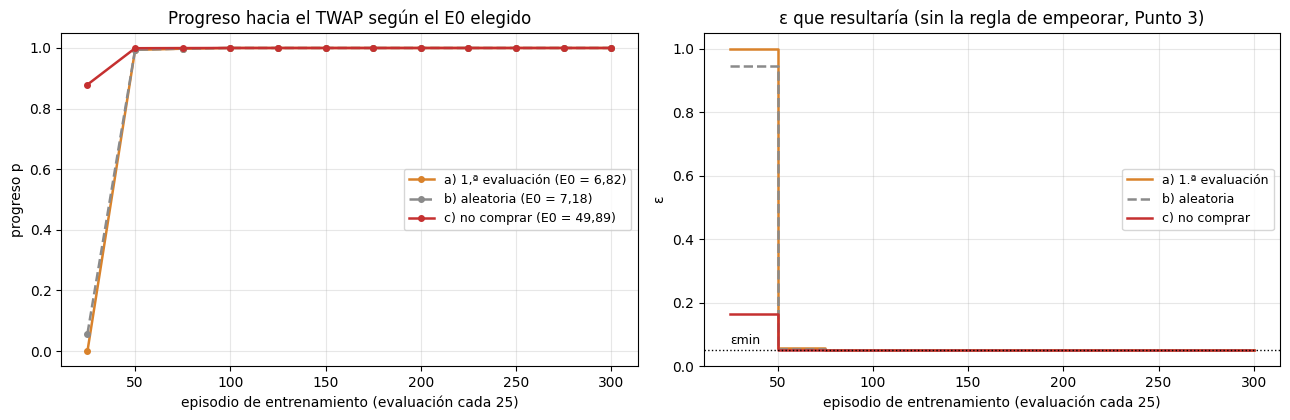

In [9]:
ej3.plot_progress_e0(ev1, E0S, PCOL, TWAP_ERR, save_as="ej3_p2c_progreso_segun_e0");

**Lectura.** Con E = 20 títulos, las opciones a (E0 = 6,82) y b (7,18) dan p = 0, porque 20 es peor que su punto de partida; la c da 0,61. En la ejecución del Punto 1, las tres opciones llegan a p = 0,99 en el episodio 50 y a p = 1 desde el 75, y ε queda en el mínimo: con un agente que aprende tan rápido, la elección de E0 apenas importa al final. **Importa al principio:** con la opción a, la primera evaluación da p = 0 por construcción y ε sigue en 1 hasta la segunda; con la c, esa misma evaluación ya vale p = 0,88 y ε bajaría a 0,17 en el episodio 25. El Punto 4 muestra lo que cuesta eso.

### 2.d · Límites y salvaguardas

| Situación | Qué pasa con este diseño | Salvaguarda |
|---|---|---|
| El agente **supera al TWAP** (E < E\*) | p se recorta a 1 y ε queda en εmin = 0,05, **no en 0**: dejar de explorar es dejar de aprender (T06 ~03:02) | Opcional: **nivel de aspiración móvil** (APP p.66; 10 §7.3): si p ≥ 1 durante varias evaluaciones, subir el listón (p. ej. la política miope óptima de la recompensa) y marcarlo en el gráfico de ε |
| El agente **nunca se acerca** | p ≈ 0 y ε se queda alta para siempre: el agente no sale del azar | Plan B, a elegir en el Punto 3: tope de episodios (doble criterio, T06 ~03:04-03:05), decaimiento lento de fondo declarado, o parar y revisar la configuración. No es teórico: con la configuración de partida del ej. 2 (escenario B del Punto 4) y ε lineal, la semilla 0 acaba en 15,1 títulos tras 300 episodios |
| **E0 varía entre ejecuciones** (riesgo de la opción a, asumido) | El mismo E da distinto progreso según la semilla y el plan de ε | Se medirá en el Punto 4: cuánto varía E0 entre las 3 semillas. Si varía mucho, se cambia a la opción c (fija) |
| E0 ya está por debajo de E\* | No hay camino que recorrer | `base_error = max(E0, E*)` → p = 1 y ε al mínimo |

### Decisión del Punto 2

| Elemento | Valor | Motivo |
|---|---|---|
| **E0** | Primera evaluación greedy del propio agente (opción a) | Mide la mejora del agente frente a su propio punto de partida |
| **E\*** | Error máximo medio del TWAP determinista en la rejilla: 0,90 títulos | *Benchmark* clásico sin ML y objetivo del ej. 2 |
| **Progreso** | $p = \mathrm{clip}((E_0 - E)/(E_0 - E^*), 0, 1)$ | Fracción del camino recorrido, en [0, 1] |
| **Salvaguardas** | Recorte a [0, 1], εmin = 0,05 > 0, plan B si nunca mejora (Punto 3), variabilidad de E0 revisada en el Punto 4 (alternativa: opción c) | |

> **Revisión (Punto 5):** la variabilidad de E0 se confirmó (6,4-15,0 títulos entre semillas en el escenario A) y la opción a arrancaba con ε = 1 hasta 50-75 episodios. La decisión final es la **variante d**: E0 fijo = 49,89 («no comprar») y progreso en **escala logarítmica**. Ver 5.a-5.d.

---
## Punto 3 · ¿Cómo pasa la mejora a ε?

Con el progreso $p \in [0, 1]$ del Punto 2, ε es **lineal en el progreso**:

$$\varepsilon = \varepsilon_{max} - (\varepsilon_{max} - \varepsilon_{min})\cdot p_{ref},\qquad \varepsilon_{max} = 1,\ \ \varepsilon_{min} = 0{,}05$$

Es la regla X2 de la hoja de ruta (10 §7.3): «ya está a mitad del objetivo, puedo bajar un poco la exploración» (T06 ~03:19).
Se empieza en ε = 1 porque al principio el agente no sabe nada, y nunca se baja a 0 mientras se entrena: **dejar de explorar es
dejar de aprender**, y ε = 0 es la puesta en producción (T06 ~03:01-03:02; 04 §2.1), que aquí es nuestra evaluación greedy.
Quedan tres decisiones: qué progreso usar ($p_{ref}$), cuándo creer que el agente ha empeorado y qué hacer entonces.

### 3.a · ¿El último progreso o el mejor?

**Decisión:** $p_{ref}$ es el **mejor** progreso alcanzado, no el último.

Primero, la serie del Punto 1 (escenario A). Después, para ver qué pasa cuando el aprendizaje se tuerce, la del **escenario B**
del Punto 4 (configuración de partida del ej. 2, semilla 0, ε lineal), que es inestable.

episode,25,50,75,100,125,150,175,200,225,250,275,300
A · metric,6.82,0.94,0.91,0.9,0.9,0.9,0.9,0.9,0.9,0.9,0.9,0.9
A · progress,0.0,0.99,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A · epsilon,1.0,0.06,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05
A · rise,False,False,False,False,False,False,False,False,False,False,False,False


episode,25,50,75,100,125,150,175,200,225,250,275,300
B · p,0.0,0.41,0.33,0.29,0.60,0.52,0.51,0.11,0.86,0.53,0.63,0.70
B · ε (último p),1.0,0.61,0.69,0.72,0.43,0.50,0.52,0.89,0.18,0.49,0.40,0.33
B · ε (mejor p),1.0,0.61,0.61,0.61,0.43,0.43,0.43,0.43,0.18,0.18,0.18,0.18


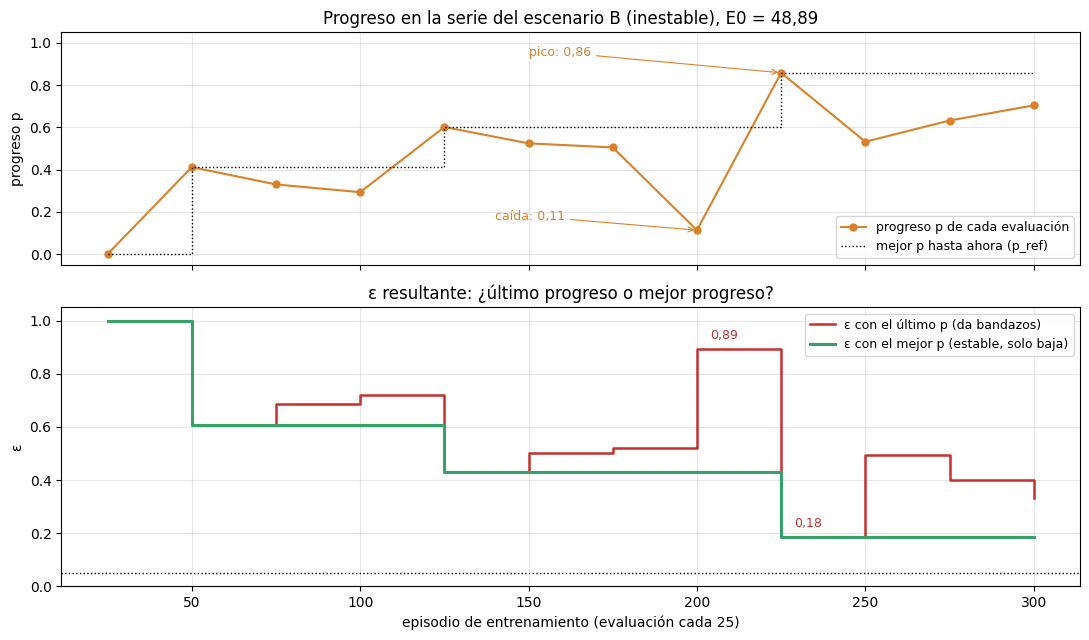

In [10]:
P1 = ej3.replay(ev1.max_err, TWAP_ERR).assign(episode=ev1.episode)        # escenario A: E0 = 1.ª evaluación, E* = TWAP
EVB = ej3.load_run("inestable", "lineal", 0)[1]                           # escenario B, semilla 0, ε lineal (caché)
PB = ej3.replay(EVB.max_err, TWAP_ERR).assign(episode=EVB.episode)
display(P1.set_index("episode")[["metric", "progress", "epsilon", "rise"]].T.rename(index=lambda i: f"A · {i}"))
ej3.plot_last_vs_best(PB.episode, PB.progress, title=f"Progreso en la serie del escenario B (inestable), E0 = {PB.metric.iloc[0]:.2f}".replace(".", ","),
                      save_as="ej3_p3a_ultimo_vs_mejor");
pd.DataFrame({"p": PB.progress.values, "ε (último p)": 1 - 0.95 * PB.progress.values,
              "ε (mejor p)": 1 - 0.95 * np.maximum.accumulate(PB.progress.values)}, index=PB.episode).T.rename(index=lambda i: f"B · {i}")

**Lectura.** **Escenario A:** el progreso pasa de 0 a 0,99 en el episodio 50 y a 1 desde el 75, y no vuelve a bajar. Las dos reglas dan lo mismo (ε = 1 → 0,06 → 0,05) y la diferencia no se ve. **Escenario B (figura):** atado al último progreso, ε da bandazos: 0,52 en el episodio 175, **0,89** en el 200 (el progreso cae a 0,11) y **0,18** en el 225 (pico de 0,86), y luego vuelve a 0,49. Son cambios de casi 0,7 en 25 episodios, que en un entrenamiento real llenarían el buffer de experiencias aleatorias justo después de un mal resultado. Con el mejor progreso, ε solo baja (1 → 0,61 → 0,43 → 0,18) y es estable. Tiene el defecto contrario: una sola evaluación buena (la del 225) la deja en 0,18 aunque las tres siguientes estén muy por debajo (0,53; 0,63; 0,70). Hace falta una regla para salir de ahí (3.c).

### 3.b · ¿Ruido o empeoramiento real?

La evaluación es **determinista**: mismos 27 episodios, política greedy (sin azar en la acción) y red congelada. Por tanto, el
mismo agente da siempre el mismo E. Se comprueba evaluando dos veces una red recién creada:

In [11]:
pr.set_seeds(0)
probe = DDQNAgent(BestExecutionEnv(train, reward=REWARD, seed=0), seed=0, **CFG)
e1, e2 = (pr.evaluate(probe, train, GRID, reward=REWARD, with_twap=False).max_err for _ in range(2))
print(f"1.ª evaluación: {e1.mean():.4f} · 2.ª: {e2.mean():.4f} · episodios idénticos: {(e1.values == e2.values).all()}")
EVB.loc[EVB.episode.between(150, 225), ["episode", "max_err", "epsilon"]]          # escenario B

1.ª evaluación: 44.7027 · 2.ª: 44.7027 · episodios idénticos: True


,episode,max_err,epsilon
5,150,23.72,0.05
6,175,24.65,0.05
7,200,43.45,0.05
8,225,7.69,0.05


**Lectura.** Dos evaluaciones seguidas del mismo agente dan exactamente el mismo error (44,7027 títulos) en los 27 episodios. Por tanto, un salto en E es un **cambio real de la política**, no ruido de medida. En el escenario A no hay saltos: desde el episodio 100 todas las evaluaciones dan 0,90. En el B, el salto del episodio 200 (de 24,65 a 43,45 títulos) llegó con ε = 0,05 desde hacía 50 episodios. No lo causa la exploración, sino la inestabilidad del propio aprendizaje, y en la evaluación siguiente el agente baja a 7,69.

Así que la pregunta no es si el salto es real, sino si es **pasajero o persistente**. El RL con redes es inestable y puede
olvidar de golpe lo aprendido (*catastrophic forgetting*, 04 §8 y §9.3; APP p.88): eso pide reaccionar, pero solo cuando el
empeoramiento se confirma. De ahí el **margen** (cuánto peor) y la **paciencia** (cuántas evaluaciones seguidas).

### 3.c · La regla para volver a subir ε

**Decisión:** si $p < p_{ref} - 0{,}1$ durante **2 evaluaciones seguidas**, se baja $p_{ref}$ al progreso actual y ε sube
**solo hasta lo que corresponde a ese progreso**, no a 1 (`ImprovementEpsilon`, D-3.1; «si empeora, se puede volver a subir la
exploración», 04 §3.4; T06 ~03:21).

**Por qué no volver a 1:** con ε = 1 el agente vuelve a ser aleatorio y el buffer se llena de experiencias al azar que pueden
hacerle olvidar lo aprendido. Explorar más «aunque tarde más» es razonable al principio, pero la exploración no es infinita
(T06 ~03:19) y la exploración ineficiente hace que **la red se sobreajuste a experiencias malas** (04 §3.6; T06 ~03:06-03:09).
Por eso la regla solo reacciona a un empeoramiento confirmado y en la medida de ese empeoramiento.

Se reproduce `ImprovementEpsilon` *offline* sobre la serie real del escenario B (en la del A no hay ningún empeoramiento que
la active), frente a dos variantes: no subir nunca y volver a ε = 1.

episode,25,50,75,100,125,150,175,200,225,250,275,300
metric,48.89,29.13,33.05,34.82,20.01,23.72,24.65,43.45,7.69,23.35,18.54,15.09
progress,0.0,0.41,0.33,0.29,0.6,0.52,0.51,0.11,0.86,0.53,0.63,0.7
ref,0.0,0.41,0.41,0.41,0.6,0.6,0.6,0.6,0.86,0.86,0.63,0.7
epsilon,1.0,0.61,0.61,0.61,0.43,0.43,0.43,0.43,0.18,0.18,0.4,0.33
rise,False,False,False,False,False,False,False,False,False,False,True,False


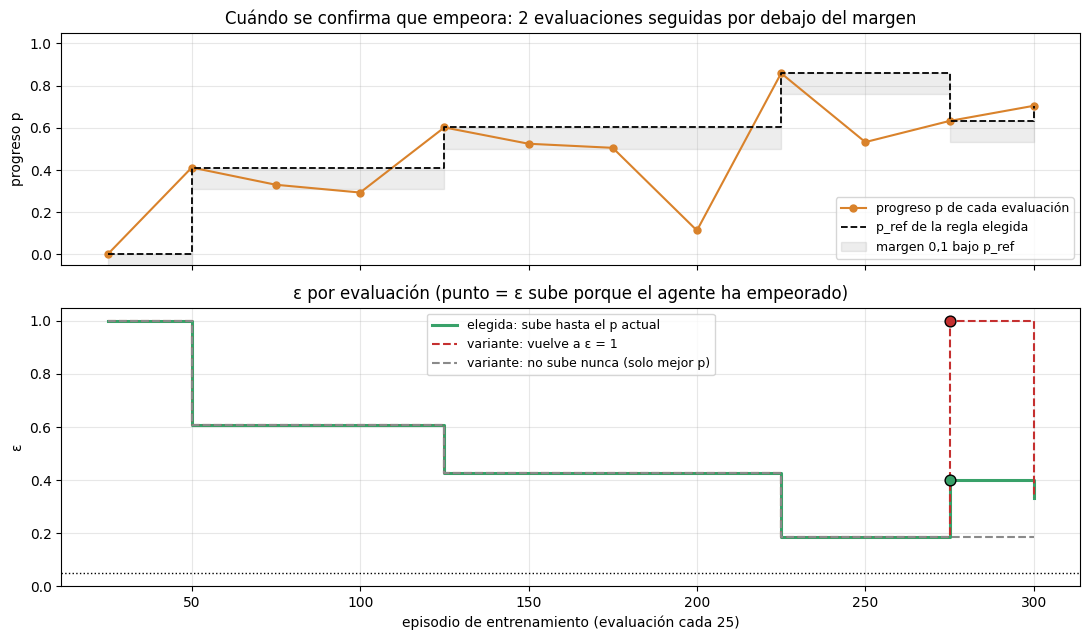

In [12]:
VARIANTS = {"elegida: sube hasta el p actual": PB,
            "variante: vuelve a ε = 1": ej3.replay(EVB.max_err, TWAP_ERR, reset_to_max=True),
            "variante: no sube nunca (solo mejor p)": ej3.replay(EVB.max_err, TWAP_ERR, patience=10**9)}
VCOL = dict(zip(VARIANTS, [ej3.EPS, "#C53030", "#8A8A8A"]))
ej3.plot_rise_rule(PB.episode, VARIANTS, VCOL, save_as="ej3_p3c_regla_subida");
PB.set_index("episode")[["metric", "progress", "ref", "epsilon", "rise"]].T

**Lectura.** En el escenario A la regla no se activa nunca: el progreso no baja de 1 tras el episodio 75. En el B, la caída del episodio 200 (0,11) no hace subir ε: es una sola evaluación y la siguiente marca el mejor progreso (0,86). Tras el pico, el progreso queda dos veces seguidas por debajo de 0,86 − 0,1 = 0,76 (0,53 en el 250 y 0,63 en el 275). Por eso, en el **episodio 275**, $p_{ref}$ baja de 0,86 a 0,63 y **ε sube de 0,18 a 0,40**. En el 300 vuelve a bajar a 0,33 porque el progreso mejora (0,70). La variante «volver a ε = 1» habría pasado de 0,18 a 1 de golpe: 25 episodios de acciones al azar para un agente que conserva el 63 % del camino. La variante «no subir nunca» deja ε en 0,18 hasta el final.

### 3.d · Sensibilidad: margen × paciencia

escenario A: subidas de ε en las 9 combinaciones → [0, 0, 0, 0, 0, 0, 0, 0, 0]


,margen,paciencia,subidas de ε,episodios de las subidas,ε medio,ε final
0,0.05,1,4,"75, 150, 200, 250",0.56,0.33
1,0.05,2,3,"100, 175, 275",0.49,0.33
2,0.05,3,2,"200, 300",0.49,0.33
3,0.10,1,3,"100, 200, 250",0.54,0.33
4,0.10,2,1,275,0.47,0.33
5,0.10,3,1,300,0.45,0.33
6,0.20,1,2,"200, 250",0.53,0.33
7,0.20,2,1,275,0.47,0.33
8,0.20,3,0,—,0.44,0.18


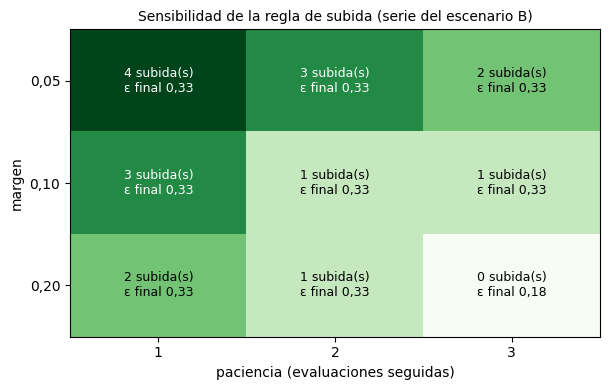

In [13]:
SENS = ej3.sensitivity(EVB.max_err, TWAP_ERR)                                 # escenario B
print("escenario A: subidas de ε en las 9 combinaciones →", ej3.sensitivity(ev1.max_err, TWAP_ERR)["subidas de ε"].tolist())
ej3.plot_sensitivity(SENS, save_as="ej3_p3d_sensibilidad");
SENS

**Lectura.** En el escenario A no hay ninguna subida en las 9 combinaciones: sin empeoramientos, el margen y la paciencia no importan. En el B, con paciencia 1 la regla reacciona a evaluaciones sueltas: con margen 0,1 sube ε en los episodios 100, 200 y 250, incluida la caída pasajera del 200, que la evaluación siguiente recupera. Con paciencia 2 y margen 0,1 o 0,2 hay **una sola subida** (episodio 275), la del empeoramiento sostenido tras el pico. Un margen de 0,05 es demasiado sensible (3 subidas incluso con paciencia 2) y la combinación 0,2 × 3 no reacciona nunca (ε final 0,18). El ε final es 0,33 en 8 de las 9 combinaciones; lo que cambia es cuántas veces se vuelve a explorar por el camino (ε medio de 0,44 a 0,56).

**Limitación:** es una reproducción *offline* sobre una serie ya medida con ε lineal. En un entrenamiento real, ε cambia lo que
el agente explora y, con ello, la propia serie de E; el efecto real de la regla se mide en el Punto 4.

### Decisión del Punto 3

| Elemento | Valor | Motivo |
|---|---|---|
| Fórmula | $\varepsilon = \varepsilon_{max} - (\varepsilon_{max} - \varepsilon_{min})\cdot p_{ref}$ | Lineal en la fracción del camino hacia el TWAP (X2) |
| εmax / εmin | 1 / 0,05 | Se empieza sin saber nada; nunca 0 mientras se entrena |
| $p_{ref}$ | Mejor progreso alcanzado | Estable frente a los saltos de la evaluación (3.a) |
| Empeora si | $p < p_{ref} - 0{,}1$ en 2 evaluaciones seguidas | La evaluación es determinista; se filtran los saltos pasajeros (3.b, 3.d) |
| Al empeorar | $p_{ref} \leftarrow p$: ε sube hasta lo que corresponde al progreso actual, no a 1 | No volver al azar ni llenar el buffer de experiencias malas (3.c) |
| Frecuencia | Evaluación greedy cada 25 episodios en la rejilla de 27 | Punto 1; entre evaluaciones ε no cambia, sea cual sea el número de episodios |

**Respuestas al enunciado**

- **¿Cómo determinamos que el algoritmo ha mejorado?** Cada 25 episodios paramos la exploración y evaluamos la política greedy
  en los mismos 27 episodios de la rejilla; la mejora es la bajada del error máximo de seguimiento medio, expresada como la
  fracción del camino recorrido desde la primera evaluación del agente hasta el TWAP determinista.
- **¿Cómo trasladamos esa mejora a ε?** ε baja linealmente con el mejor progreso alcanzado, de 1 a 0,05; si el agente empeora
  más de 0,1 en dos evaluaciones seguidas, ε vuelve a subir hasta el valor que corresponde a su progreso actual.

---
## Punto 4 · ¿Cómo demostramos que funciona?

Se entrena el mismo agente con **ε lineal** (el del LAB, la referencia) y con **ε por mejora** (`ImprovementEpsilon`, Puntos
1-3), con 3 semillas (0, 1, 2), en dos escenarios:

- **A · Configuración final del ej. 2** (la de todo este notebook): es la que se entrega.
- **B · Configuración de partida del ej. 2, inestable:** `Tracking` con c = 5 y sin cierre, buffer de 50.000. El ej. 2 la
  descartó (D-2.5, D-2.6, D-2.7) porque aprende de forma irregular; aquí sirve para ver qué hace cada plan de ε cuando el
  aprendizaje se tuerce. Sus 6 ejecuciones están cacheadas y no se reentrenan. (Con `learn_after = 4` también aprendía,
  coherente con D-2.4.)

### 4.a · Protocolo: solo cambia el plan de ε

| Qué | Igual en los dos planes | Por qué |
|---|---|---|
| Configuración del agente | Misma recompensa, red, γ, α, buffer, batch, `learn_after`, `update_target_after` y 300 episodios | Aislar el efecto de ε |
| Semilla | 0, 1 y 2 para agente, entorno y PyTorch | Mismas condiciones iniciales por pareja |
| Llenado del buffer | 25 episodios aleatorios con la misma semilla | Mismo punto de partida |
| Episodios de entrenamiento | La misma secuencia (día, hora, N, n): el entorno tiene su propio generador y la exploración usa el del agente (D-1.3) | Que la exploración no cambie los episodios |
| ε inicial | 1 en los dos (`sched.init(agent)`) | Se empieza sin saber nada (04 §2.1) |
| ε mínimo | 0,05 | Nunca 0 mientras se entrena |
| Evaluación | Greedy cada 25 episodios en la misma rejilla de 27, **también con ε lineal** (que no la usa para decidir) | Medir los dos con la misma vara |

`ej3.run_all` lanza en paralelo (4 procesos) las ejecuciones que falten y las cachea en `results/ej3_p4_runs/`; con la caché,
la celda tarda segundos.

In [14]:
EV4, TR4 = ej3.run_all(("final", "inestable"), target=TWAP_ERR)      # ~6 min la primera vez (escenario A)
pr.save_df(EV4, "ej3_p4_evals"); pr.save_df(TR4, "ej3_p4_train")
TITLES = {"final": "A · configuración final del ej. 2", "inestable": "B · configuración de partida (inestable)"}

### 4.b · Resultados: E y ε a lo largo del entrenamiento

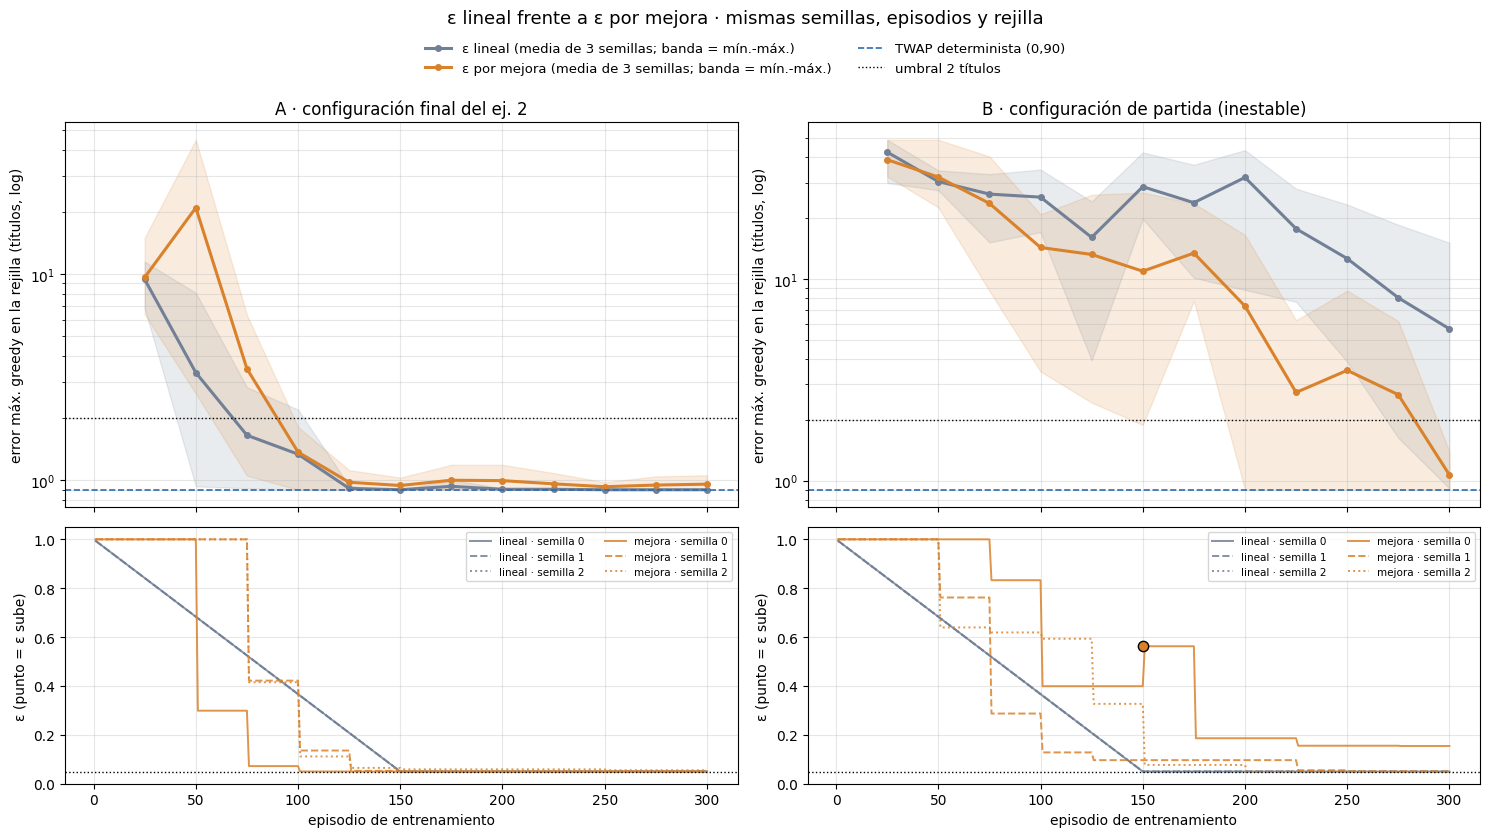

In [15]:
ej3.plot_comparison(EV4, TR4, ["final", "inestable"], titles=TITLES, save_as="ej3_p4c_comparacion");

### 4.c · Métricas (media ± desviación de 3 semillas) y E0 por semilla

E final = última evaluación; área E = altura media de la curva de E (área bajo la curva entre la primera y la última
evaluación, dividida por los episodios; menor es mejor y no necesita umbral); ε medio = exploración gastada por episodio.

In [16]:
M4 = pd.DataFrame([{"escenario": TITLES[c][:1], "plan": s, "semilla": seed, **ej3.run_metrics(
        TR4[(TR4.config == c) & (TR4.schedule == s) & (TR4.seed == seed)],
        EV4[(EV4.config == c) & (EV4.schedule == s) & (EV4.seed == seed)].sort_values("episode"))}
      for (c, s, seed), _ in EV4.groupby(["config", "schedule", "seed"])])
fmt = lambda g: pd.Series({k: f"{g[k].mean():.2f} ± {g[k].std():.2f}".replace(".", ",") for k in
                           ["E final", "E mejor", "área E (media)", "ε medio", "subidas de ε"]} |
                          {"1.er ep. E ≤ 2": f"{g['1.er ep. E ≤ 2'].notna().sum()}/3 · " +
                           (f"{g['1.er ep. E ≤ 2'].mean():.0f}" if g["1.er ep. E ≤ 2"].notna().any() else "—")})
display(M4.groupby(["escenario", "plan"]).apply(fmt, include_groups=False))
M4.pivot_table(index="semilla", columns=["escenario", "plan"], values="E0")

E final      E mejor área E (media)      ε medio  \
escenario plan                                                           
A         lineal  0,90 ± 0,00  0,90 ± 0,00    1,62 ± 0,63  0,29 ± 0,00   
          mejora  0,96 ± 0,09  0,93 ± 0,05    3,44 ± 2,00  0,29 ± 0,06   
B         lineal  5,65 ± 8,18  3,18 ± 3,91   22,26 ± 5,74  0,29 ± 0,00   
          mejora  1,07 ± 0,28  1,06 ± 0,28   13,07 ± 7,23  0,40 ± 0,10   

                 subidas de ε 1.er ep. E ≤ 2  
escenario plan                                
A         lineal  0,00 ± 0,00       3/3 · 75  
          mejora  0,00 ± 0,00       3/3 · 92  
B         lineal  0,00 ± 0,00      2/3 · 288  
          mejora  0,33 ± 0,58      3/3 · 225

escenario      A             B       
plan      lineal mejora lineal mejora
semilla                              
0           6.82   7.51  48.89  48.89
1           9.95   6.38  29.88  32.19
2          11.47  15.01  48.69  35.89

**Lectura (sin conclusión; esa va en el Punto 5).** **Escenario A (final).** Los dos planes replican el TWAP, pero **ε lineal es algo mejor**. Termina en 0,90 ± 0,00 en las 3 semillas, frente a 0,96 ± 0,09 con ε por mejora: la semilla 2 se queda entre 0,98 y 1,19 desde el episodio 125, con ε = 0,06. El área bajo la curva es 1,62 ± 0,63 frente a 3,44 ± 2,00, y baja de 2 títulos antes (episodio 75 frente a 92 de media; las 3 semillas en los dos casos). El ε medio es el mismo (0,29) y no hay ninguna subida de ε. La diferencia está al principio, por la opción a del Punto 2: la primera evaluación da p = 0 por construcción, así que ε sigue en 1 al menos hasta el episodio 50, cuando el lineal ya va por 0,68. En las semillas 1 y 2 la segunda evaluación empeora (de 6,38 a 44,70 y de 15,01 a 15,53) y ε sigue en 1 hasta el 75. Esta configuración aprende precisamente entre los episodios 25 y 75, y explorar del todo en ese tramo la retrasa.

**Escenario B (inestable).** Al revés: ε por mejora termina en 1,07 ± 0,28 títulos frente a 5,65 ± 8,18. La dispersión del lineal la causa la semilla 0, la serie del Punto 3, que acaba en 15,1; las semillas 1 y 2 llegan a 0,9 solo en el episodio 300. El área es 13,07 ± 7,23 frente a 22,26 ± 5,74, y las 3 semillas bajan de 2 títulos (de media en el episodio 225) frente a 2 de 3 con lineal (episodio 288). A cambio, explora más (ε medio 0,40 frente a 0,29), con una subida de ε (semilla 0, episodio 150).

**E0 por semilla.** En A varía entre 6,38 y 15,01, y siempre queda cerca de la aleatoria (7,18), muy lejos de «no comprar» (49,89). En B varía entre 29,88 y 48,89. El E0 del lineal difiere del de ε por mejora con la misma semilla porque en los 25 primeros episodios ε ya baja hasta 0,84 en el lineal. Con la opción c (E0 fijo = 49,89), la primera evaluación del escenario A valdría p ≈ 0,7-0,9 y ε bajaría ya en el episodio 25 (2.c): es la alternativa a valorar en el Punto 5.

---
## Punto 5 · Resultados y conclusión

El Punto 4 deja una pista: en el escenario A, ε por mejora pierde al principio porque la opción a (E0 = primera evaluación)
da p = 0 por construcción. Se prueban dos variantes de E0 con las mismas 3 semillas y los dos escenarios (12 ejecuciones
nuevas; `ImprovementEpsilon` admite ahora `base_error` y `log_scale`, con el comportamiento original por defecto):

| Plan | E0 | Escala de p |
|---|---|---|
| a) `mejora` (Puntos 2-4) | Primera evaluación del agente | Lineal |
| c) `mejora_c` | Fijo: error de «no comprar» = n medio de la rejilla | Lineal |
| d) `mejora_d` | Fijo: el mismo | Logarítmica: $p = \mathrm{clip}\big((\ln E_0 - \ln E)/(\ln E_0 - \ln E^*), 0, 1\big)$ |

### 5.a · El problema de la escala

,E = 20,E = 7,E = 2
c) lineal,0.61,0.88,0.98
d) log,0.23,0.49,0.80


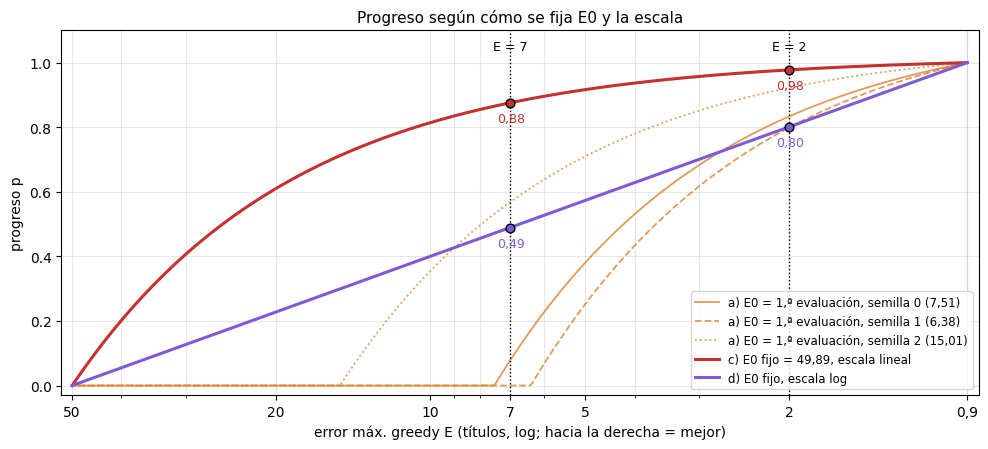

In [17]:
E0_FIX = float(np.mean([c["vol_care"] for c in GRID]))                    # = error de «no comprar»
assert np.isclose(E0_FIX, NOBUY_GRID.max_err.mean())
E0_A = EV4[(EV4.config == "final") & (EV4.schedule == "mejora") & (EV4.episode == 25)].sort_values("seed").max_err.values
ej3.plot_scale(E0_A, E0_FIX, TWAP_ERR, save_as="ej3_p5a_escala");
pd.DataFrame({f"E = {E}": {"c) lineal": float(ej3.progress(E, E0_FIX, TWAP_ERR)),
                           "d) log": np.log(E0_FIX / E) / np.log(E0_FIX / TWAP_ERR)} for E in (20, 7, 2)})

**Lectura.** El error recorre casi dos órdenes de magnitud, de 49,89 (no comprar) a 0,90 (TWAP). Con la opción **c** (E0 fijo y escala lineal), el tramo fácil de 49,89 a 7 títulos, que el agente recorre casi solo en los primeros episodios, ya vale **p = 0,88**; quedan 0,12 de escala para lo difícil (de 7 a 0,9), así que ε cae casi al mínimo en cuanto el agente deja de ser aleatorio. Con la opción **a**, E0 depende de la semilla (6,38 / 7,51 / 15,01 en el escenario A) y todo lo que quede por encima de E0 vale p = 0. Con la opción **d** (escala logarítmica), cada vez que el error se divide por dos cuenta lo mismo (0,17 de progreso): E = 20 → 0,23; E = 7 → 0,49; E = 2 → 0,80.

### 5.b · Resultados: cuatro planes en los dos escenarios

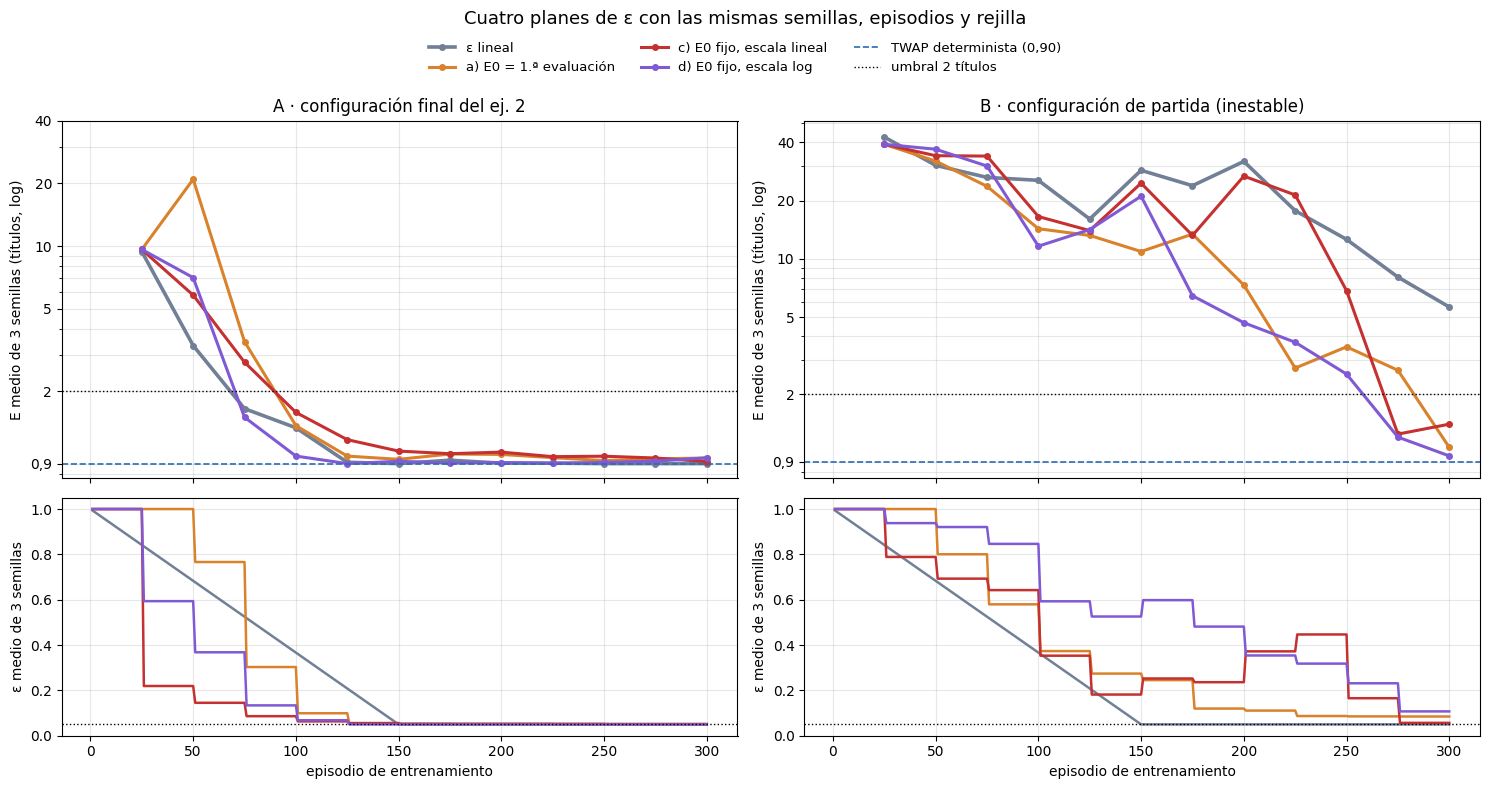

In [18]:
EV5, TR5 = ej3.run_all(("final", "inestable"), target=TWAP_ERR, schedules=ej3.ALL_SCHEDULES)   # ~8 min la 1.ª vez
pr.save_df(EV5, "ej3_p5_evals"); pr.save_df(TR5, "ej3_p5_train")
ej3.plot_comparison4(EV5, TR5, ["final", "inestable"], TITLES, save_as="ej3_p5b_cuatro_planes");

In [19]:
M5 = pd.DataFrame([{"escenario": TITLES[c][:1], "plan": ej3.SCHED5[s][0], "semilla": seed, **ej3.run_metrics(
        TR5[(TR5.config == c) & (TR5.schedule == s) & (TR5.seed == seed)],
        EV5[(EV5.config == c) & (EV5.schedule == s) & (EV5.seed == seed)].sort_values("episode"))}
      for (c, s, seed), _ in EV5.groupby(["config", "schedule", "seed"])])
ORDER = [v[0] for v in ej3.SCHED5.values()]
T5 = M5.groupby(["escenario", "plan"]).apply(fmt, include_groups=False)
T5 = T5.reindex(pd.MultiIndex.from_product([["A", "B"], ORDER]))
T5

E final      E mejor área E (media)  \
A ε lineal                   0,90 ± 0,00  0,90 ± 0,00    1,62 ± 0,63   
  a) E0 = 1.ª evaluación     0,96 ± 0,09  0,93 ± 0,05    3,44 ± 2,00   
  c) E0 fijo, escala lineal  0,92 ± 0,02  0,92 ± 0,03    2,05 ± 1,37   
  d) E0 fijo, escala log     0,96 ± 0,10  0,90 ± 0,00    1,93 ± 1,10   
B ε lineal                   5,65 ± 8,18  3,18 ± 3,91   22,26 ± 5,74   
  a) E0 = 1.ª evaluación     1,07 ± 0,28  1,06 ± 0,28   13,07 ± 7,23   
  c) E0 fijo, escala lineal  1,40 ± 0,59  1,25 ± 0,48   19,33 ± 3,56   
  d) E0 fijo, escala log     0,96 ± 0,09  0,96 ± 0,09   13,85 ± 4,50   

                                 ε medio subidas de ε 1.er ep. E ≤ 2  
A ε lineal                   0,29 ± 0,00  0,00 ± 0,00       3/3 · 75  
  a) E0 = 1.ª evaluación     0,29 ± 0,06  0,00 ± 0,00       3/3 · 92  
  c) E0 fijo, escala lineal  0,16 ± 0,03  0,00 ± 0,00       3/3 · 83  
  d) E0 fijo, escala log     0,21 ± 0,04  0,00 ± 0,00       3/3 · 67  
B ε lineal                   0,29 ± 0,00  0,00 ± 0,00      2/3 · 288  
  a) E0 = 1.ª evaluación     0,40 ± 0,10  0,33 ± 0,58      3/3 · 225  
  c) E0 fijo, escala lineal  0,43 ± 0,08  1,67 ± 0,58      3/3 · 275  
  d) E0 fijo, escala log     0,58 ± 0,11  1,00 ± 0,00      3/3 · 242

**Lectura.** **Escenario A (final):** ε lineal sigue siendo el mejor en área (1,62 ± 0,63) y en error final (0,90 en las 3 semillas). Entre los planes por mejora, **d** es el mejor: área 1,93 ± 1,10, el primero en bajar de 2 títulos (episodio 67 frente a 75 del lineal) y mejor punto 0,90 en las 3 semillas, aunque la semilla 2 termina en 1,08. Le siguen c (área 2,05; ε medio 0,16, el que menos explora) y a (área 3,44). **Escenario B (inestable):** todos los planes por mejora superan al lineal (área 22,26 ± 5,74; final 5,65 ± 8,18). a da la menor área (13,07 ± 7,23) y d casi la misma (13,85 ± 4,50), con el mejor error final (0,96 ± 0,09) y menos dispersión, a cambio de explorar más (ε medio 0,58). c es el peor de los tres (área 19,33; final 1,40; 1,67 subidas de ε): baja ε pronto, tiene que volver a subirla y llega tarde a 2 títulos (episodio 275).

### 5.c · Predicción frente a resultado

Antes de entrenar las variantes c y d se apuntaron dos predicciones:

| Quién | Predicción | Resultado |
|---|---|---|
| Usuario | a) será el mejor plan en los dos escenarios | **Falla en A** (a es el peor de los cuatro: área 3,44 frente a 1,62 del lineal) y **acierta a medias en B** (menor área, 13,07, pero d termina mejor: 0,96 frente a 1,07) |
| Coordinador | c) arranca rápido pero baja ε demasiado pronto (malo en B); d) es el mejor equilibrio | **Acierta con c en B** (el peor plan por mejora: área 19,33, 1,67 subidas de ε) pero no del todo en A, donde c no arranca más rápido que d (episodio 83 frente a 67). **Acierta con d** como mejor equilibrio entre los planes por mejora (2.º en A y en B, mejor error final en B), aunque no supera al lineal en A |

Ninguna predicción sale entera. Lo que sí se confirma es que **la forma de medir el progreso importa más que la regla de ε**: las tres variantes usan la misma regla (mejor progreso, margen 0,1, paciencia 2) y su área en B va de 13,07 a 19,33.

### 5.d · Conclusión

**1. Respuestas al enunciado.**

- *¿Cómo determinamos que el algoritmo ha mejorado?* Cada 25 episodios paramos la exploración y evaluamos la política greedy en los mismos 27 episodios de la rejilla; la mejora es la bajada del error máximo de seguimiento medio frente al TWAP determinista (0,90 títulos), no la recompensa de entrenamiento, que va pegada a ε.
- *¿Cómo trasladamos esa mejora a ε?* ε baja linealmente, de 1 a 0,05, con el mejor progreso alcanzado hacia el TWAP, medido en escala logarítmica desde el error de no comprar (49,89 títulos); si el progreso cae más de 0,1 durante dos evaluaciones seguidas, ε vuelve a subir hasta el valor que corresponde al progreso actual.

**2. Cuándo ayuda y cuándo no.** Ayuda cuando el aprendizaje es irregular: en el escenario B, ε por mejora (d) reduce el área bajo la curva de error un 38 % (13,85 frente a 22,26) y termina en 0,96 ± 0,09 títulos frente a 5,65 ± 8,18 del lineal; además, explora más justo cuando el agente no avanza. No ayuda cuando el agente aprende rápido y de forma estable: en el escenario A, el ε lineal ya es casi óptimo (área 1,62; 0,90 en las 3 semillas) y la mejor variante por mejora (d) queda cerca (1,93), sin superarlo. Lo que sí hace el plan por mejora es **no depender del número de episodios**: con el lineal hay que acertar de antemano en qué episodio llegar a εmin.

**3. Variante recomendada: d** (E0 fijo = error de no comprar, progreso en escala logarítmica, mejor progreso, margen 0,1 y paciencia 2). Es la única que queda entre las dos mejores en los dos escenarios: la más rápida en bajar de 2 títulos en A (episodio 67) y el mejor error final en B. E0 es igual para todas las ejecuciones (no depende de la semilla, el riesgo de la opción a) y la escala log no regala el tramo fácil (el defecto de c). Con los datos, sustituye a la opción a elegida en el Punto 2; la regla de ε del Punto 3 no cambia.

**4. Limitaciones.**

- La rejilla de evaluación usa días de **train**: el profesor recomendó validar en datos no vistos (APP p.90).
- **3 semillas**: las desviaciones son grandes (en B, ± 4-7 de área) y algunas diferencias, como la de a y d en B, están dentro del ruido.
- **Coste de la evaluación:** 27 episodios greedy cada 25 de entrenamiento, ~1 episodio de evaluación por cada uno de entrenamiento (sin aprendizaje, más baratos).
- **Precio sin probar:** medir la mejora por slippage no se ha probado. Es ruidoso (1.b) y no tiene un E\* claro, porque ningún benchmark fija cuánto se puede ganar. Queda como hipótesis para la idea A del ej. 4, cuando el estado incluya información de mercado.